In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt

In [ ]:
studies = ["Ajami18", "Bauer19", "Börstler16", "Buse10", "Gopstein17a", "Gopstein17b", "Medeiros19", "Siegmund17", "Peitek18", "overall"]
def create_dict(category):
    results_dict = {"study": [], "value": [], "variant": [], "category": [] }
    for study in studies:
        curr_vals = []
        for variant in ["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]:
            results_df = pd.read_csv(f"results/results_{variant}.csv")
            results_dict["study"].append(study) 
            study_df = results_df[results_df["study"]==study]
            res = study_df[category].iloc[0]
            curr_vals.append(res)
            results_dict["value"].append(res)
            results_dict["variant"].append(variant)
            results_dict["category"].append(category)
        diff_no_order = curr_vals[1] - curr_vals[0]
        diff_no_snippet = curr_vals[2] - curr_vals[0]
        diff_combined = curr_vals[3] - curr_vals[2] - diff_no_order
        for i in range(3):
            results_dict["category"].append(category)
            results_dict["study"].append(study)
        results_dict["variant"] += ["effect order", "effect code", "interaction effect"]
        results_dict["value"] += [diff_no_order, diff_no_snippet, diff_combined]
        
    return(results_dict)
category_dataframes = {}
results_dict = {"study": [], "value": [], "variant": [], "category": [] }
for category in ["cohen_d", "pvalue", "Centaur_mean", "Centaur_std", "Llama_mean", "Llama_std"]:
    cat_dict = create_dict(category)
    for key in results_dict:
        results_dict[key]+=cat_dict[key]
results_df = (pd.DataFrame(results_dict))

 

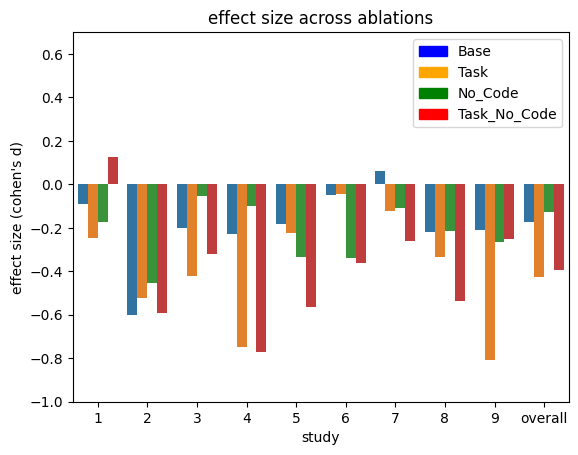

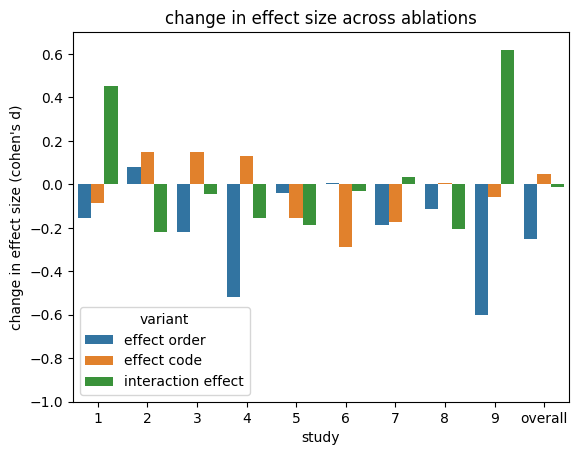

In [3]:
effect_size_df = results_df[results_df["category"] == "cohen_d"]
absolute_effect_size_df = effect_size_df[effect_size_df["variant"].isin(["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]) ]
sns.barplot(absolute_effect_size_df, x = "study", y = "value", hue = "variant")
plt.ylabel("effect size (cohen's d)")
plt.title("effect size across ablations")
plt.ylim(-1.0, 0.7)
base_patch = mpatches.Patch(color='blue', label='Base')
task_patch = mpatches.Patch(color="orange", label = "Task")
no_code_patch = mpatches.Patch(color="green", label= "No_Code")
desc_patch = mpatches.Patch(color = "red", label = "Task_No_Code")
plt.legend(handles=[base_patch, task_patch, no_code_patch, desc_patch])
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)] + ["overall"])
plt.savefig("images/ablations_effect_size.png")
plt.savefig("svgs/ablations_effect_size.svg")
plt.show()
plt.close()
relative_effect_size_df = effect_size_df[~effect_size_df["variant"].isin(["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]) ]
sns.barplot(relative_effect_size_df, x = "study", y = "value", hue = "variant")
plt.ylim(-1.0, 0.7)
plt.ylabel("change in effect size (cohen's d)")
plt.title("change in effect size across ablations")
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)] + ["overall"])
plt.savefig("images/relative_effect_size.png")
plt.savefig("svgs/relative_effect_size.svg")
plt.show()
plt.close()


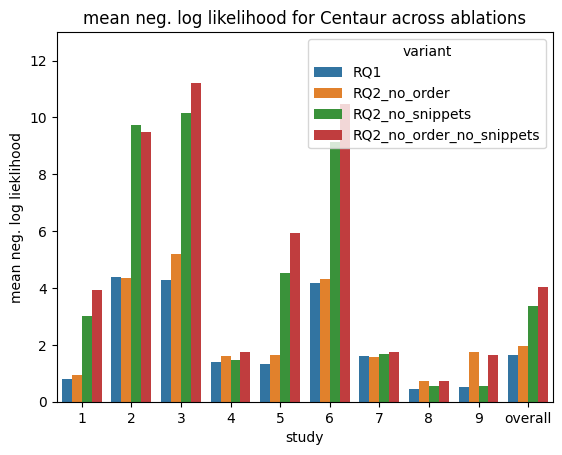

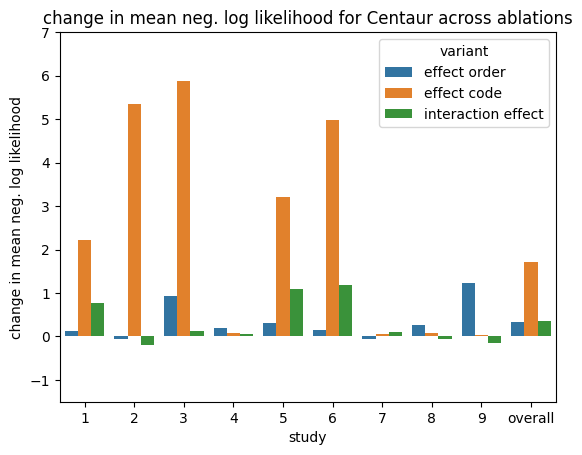

In [124]:
Centaur_mean_df = results_df[results_df["category"] == "Centaur_mean"]
absolute_centaur_mean_df = Centaur_mean_df[Centaur_mean_df["variant"].isin(["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]) ]
sns.barplot(absolute_centaur_mean_df, x = "study", y = "value", hue = "variant")
plt.ylabel("mean neg. log lieklihood")
plt.ylim(0.0, 13.0)
plt.title("mean neg. log likelihood for Centaur across ablations")
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)] + ["overall"])
plt.savefig("images/ablations_Centaur_mean.png")
plt.show()
plt.close()
relative_Centaur_mean_df = Centaur_mean_df[~Centaur_mean_df["variant"].isin(["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]) ]
sns.barplot(relative_Centaur_mean_df, x = "study", y = "value", hue = "variant")
plt.ylabel("change in mean neg. log likelihood")
plt.ylim(-1.5, 7.0)
plt.title("change in mean neg. log likelihood for Centaur across ablations")
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)] + ["overall"])
plt.savefig("images/relative_Centaur_mean.png")
plt.show()
plt.close()

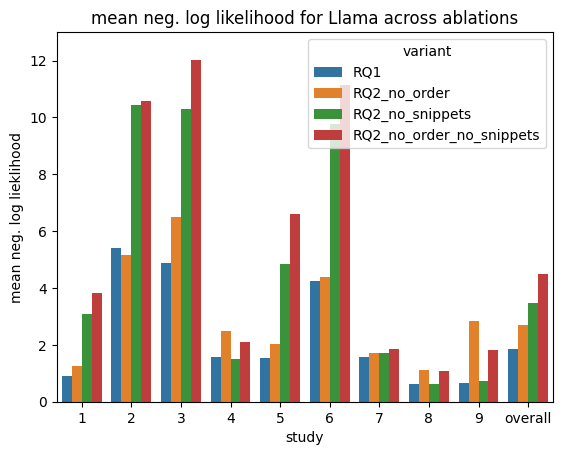

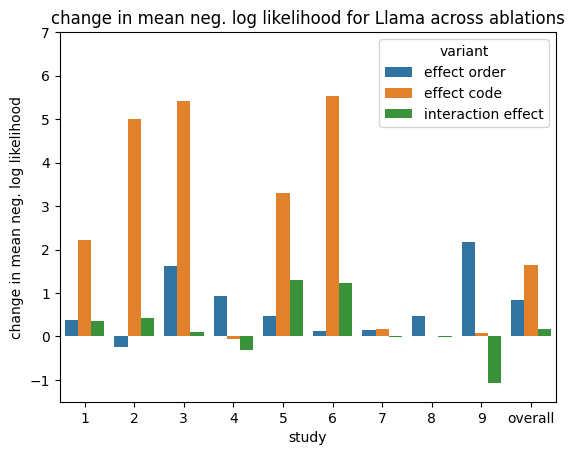

In [125]:
Llama_mean_df = results_df[results_df["category"] == "Llama_mean"]
absolute_Llama_mean_df = Llama_mean_df[Llama_mean_df["variant"].isin(["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]) ]
sns.barplot(absolute_Llama_mean_df, x = "study", y = "value", hue = "variant")
Llama_means = Llama_mean_df["value"]
plt.ylabel("mean neg. log lieklihood")
plt.ylim(0.0, 13.0)
plt.title("mean neg. log likelihood for Llama across ablations")
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)] + ["overall"])
plt.savefig("images/ablations_Llama_mean.png")
plt.show()
plt.close()
relative_Llama_mean_df = Llama_mean_df[~Llama_mean_df["variant"].isin(["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]) ]
sns.barplot(relative_Llama_mean_df, x = "study", y = "value", hue = "variant")
plt.ylabel("change in mean neg. log likelihood")
plt.ylim(-1.5, 7.0)
plt.title("change in mean neg. log likelihood for Llama across ablations")
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)] + ["overall"])
plt.savefig("images/relative_Llama_mean.png")
plt.show()
plt.close()

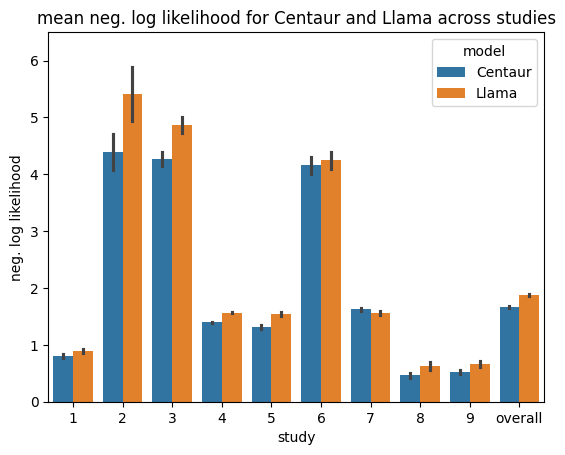

In [126]:
full_df = pd.read_csv("results/data_RQ1.csv")
full_df = full_df[full_df["study"]!="Katzmarski12"]
Centaur_full_df = full_df[full_df["model"]=="Centaur"]
Llama_full_df = full_df[full_df["model"]=="Llama"]

sns.barplot(full_df, y = "loss", x = "study", hue = "model", errorbar="se")
sns.barplot(full_df, y = "loss", x = 10, hue = "model", errorbar= "se",legend= None)
plt.ylabel("neg. log likelihood")
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)]+ ["overall"])
plt.ylim(0, 6.5)
plt.title("mean neg. log likelihood for Centaur and Llama across studies")
plt.savefig("svgs/RQ1_means.svg")
plt.savefig("images/RQ1_means.png")
plt.show()
plt.close()

In [127]:

full_dict = {"study": [], "model": [], "loss": [], "variant": []}
for variant in ["RQ1", "RQ2_no_order", "RQ2_no_snippets", "RQ2_no_order_no_snippets"]:
    var_df = pd.read_csv(f"results/data_{variant}.csv")
    for i in range(len(var_df)):
        if var_df["study"].iloc[i] == "Katzmarski12": continue
        full_dict["study"].append(var_df["study"].iloc[i])
        full_dict["model"].append(var_df["model"].iloc[i])
        full_dict["loss"].append(var_df["loss"].iloc[i])
        full_dict["variant"].append(variant)
full_df = pd.DataFrame(full_dict)
Centaur_full_df = full_df[full_df["model"]=="Centaur"]
Llama_full_df = full_df[full_df["model"]=="Llama"]

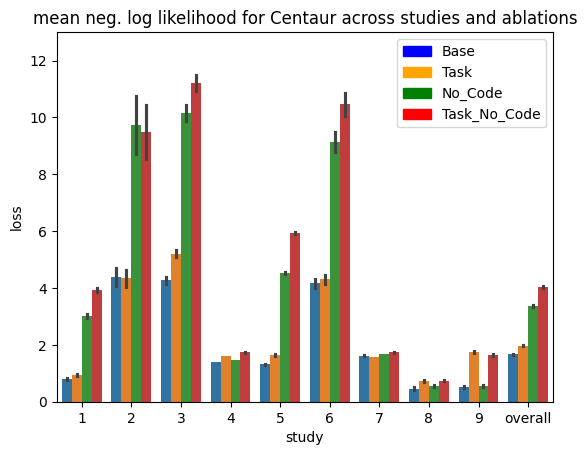

In [128]:
sns.barplot(Centaur_full_df, x = "study", y = "loss", hue = "variant", errorbar="se")
sns.barplot(Centaur_full_df, y = "loss", x = 10, hue = "variant", errorbar= "se",legend= None)
base_patch = mpatches.Patch(color='blue', label='Base')
task_patch = mpatches.Patch(color="orange", label = "Task")
no_code_patch = mpatches.Patch(color="green", label= "No_Code")
desc_patch = mpatches.Patch(color = "red", label = "Task_No_Code")
plt.ylim(0,13)
plt.legend(handles=[base_patch, task_patch, no_code_patch, desc_patch])
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)]+ ["overall"])
plt.title("mean neg. log likelihood for Centaur across studies and ablations")
plt.savefig("svgs/RQ2_means_Centaur.svg")
plt.savefig("images/RQ2_means_Centaur.png")

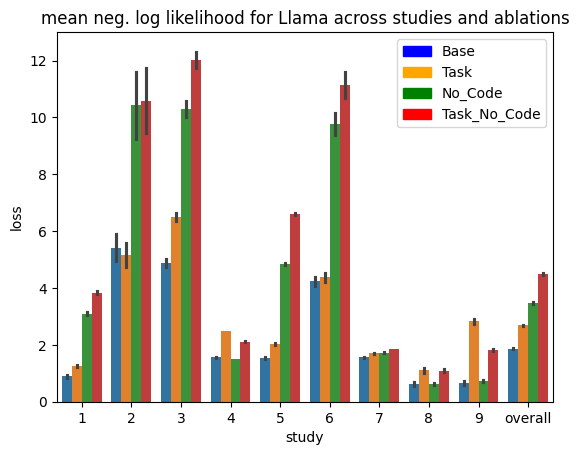

In [129]:
sns.barplot(Llama_full_df, x = "study", y = "loss", hue = "variant", errorbar="se")
sns.barplot(Llama_full_df, y = "loss", x = 10, hue = "variant", errorbar= "se",legend= None)
base_patch = mpatches.Patch(color='blue', label='Base')
task_patch = mpatches.Patch(color="orange", label = "Task")
no_code_patch = mpatches.Patch(color="green", label= "No_Code")
desc_patch = mpatches.Patch(color = "red", label = "Task_No_Code")
plt.ylim(0,13)
plt.legend(handles=[base_patch, task_patch, no_code_patch, desc_patch])
plt.xticks(ticks = plt.xticks()[0], labels = [str(i) for i in range(1,10)]+ ["overall"])
plt.title("mean neg. log likelihood for Llama across studies and ablations")
plt.savefig("svgs/RQ2_means_Llama.svg")
plt.savefig("images/RQ2_means_Llama.png")